In [1]:
from pathlib import Path
import sys

# Support kernels started in either the project root or Notebooks/Bets.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "pyproject.toml").is_file() and (folder / "src" / "ufc_betting").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting project.")
for folder in (project_root, project_root / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

In [5]:
from Notebooks.Bets.simulate_and_plot import simulate_and_plot
from ufc_betting.BettingStrategy.Backtest.backtest_plots import plot_bankroll_distributions
from ufc_betting.BettingStrategy.Backtest.backtest_plots import (
    plot_event_accuracy_distributions,
)

import pandas as pd
from ufc_betting.config import settings

# First run the final three inference cells in lr_open_close.ipynb.
# They export predictions from Data/test_data/test_data.csv to these files.
prediction_paths = {
    market: settings.model_predictions_folder / f"test_logit_open_with_{market}.csv"
    for market in ("open", "close1", "close2")
}
summary = []
for market, path in prediction_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path}. Run the test inference cells in lr_open_close.ipynb first."
        )
    predictions = pd.read_csv(path)
    dates = pd.to_datetime(predictions["date"])
    summary.append(dict(market=market, rows=len(predictions),
                        first_date=dates.min(), last_date=dates.max(), file=str(path)))
display(pd.DataFrame(summary))

,market,rows,first_date,last_date,file
0,open,295,2026-02-21,2026-10-17,C:\Users\jcmar\my_files\SportsBetting\Data\mod...
1,close1,295,2026-02-21,2026-10-17,C:\Users\jcmar\my_files\SportsBetting\Data\mod...
2,close2,295,2026-02-21,2026-10-17,C:\Users\jcmar\my_files\SportsBetting\Data\mod...


Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\test_logit_open_with_open.csv
open: decay disabled


{'z': 0.32,
 'N': 58,
 'N_parlay': 22,
 'mdd': 0.31,
 'mdd_parlay': 0.17,
 'moneyline_max_american': None,
 'decay_rates': None,
 'moneyline_min_american': -500.0}

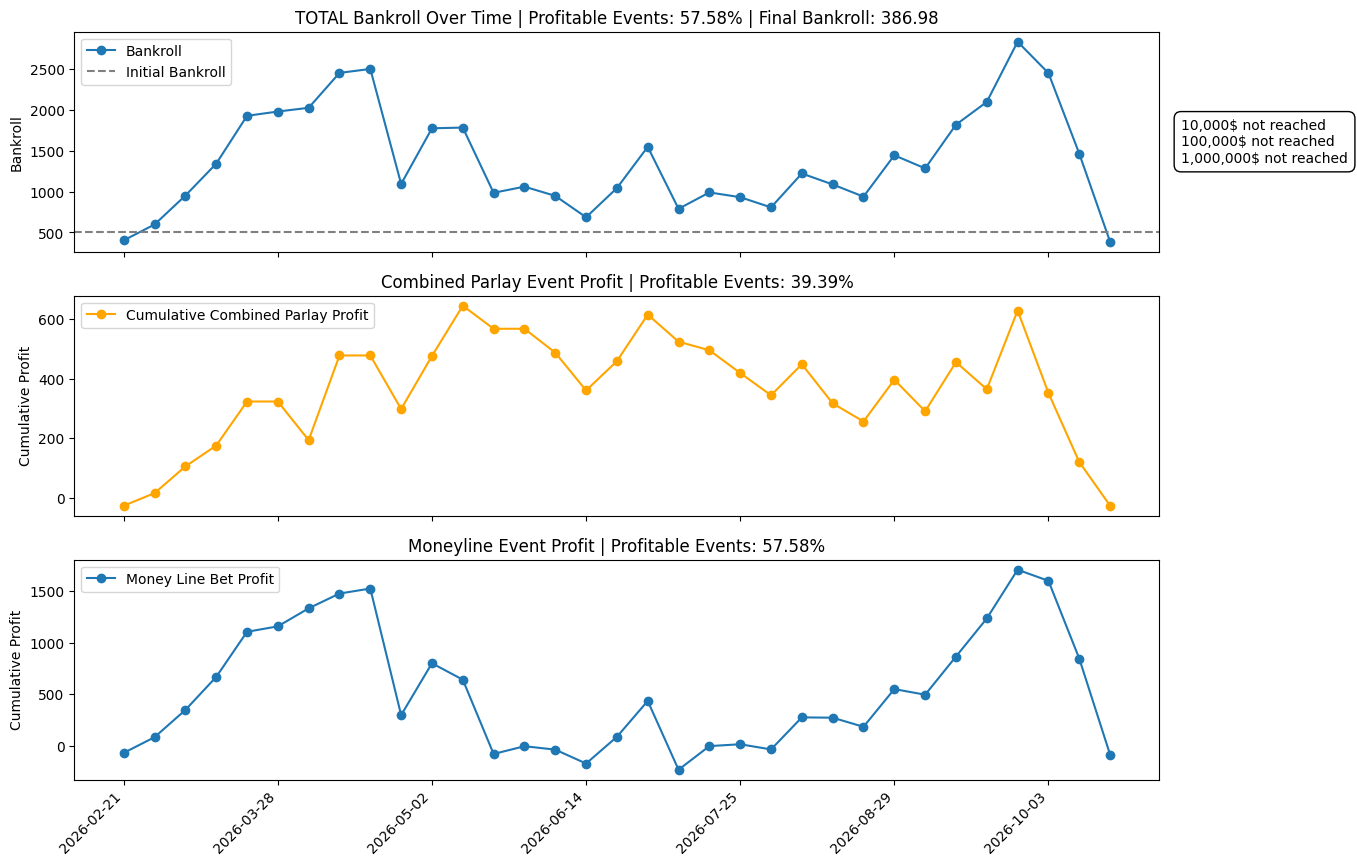

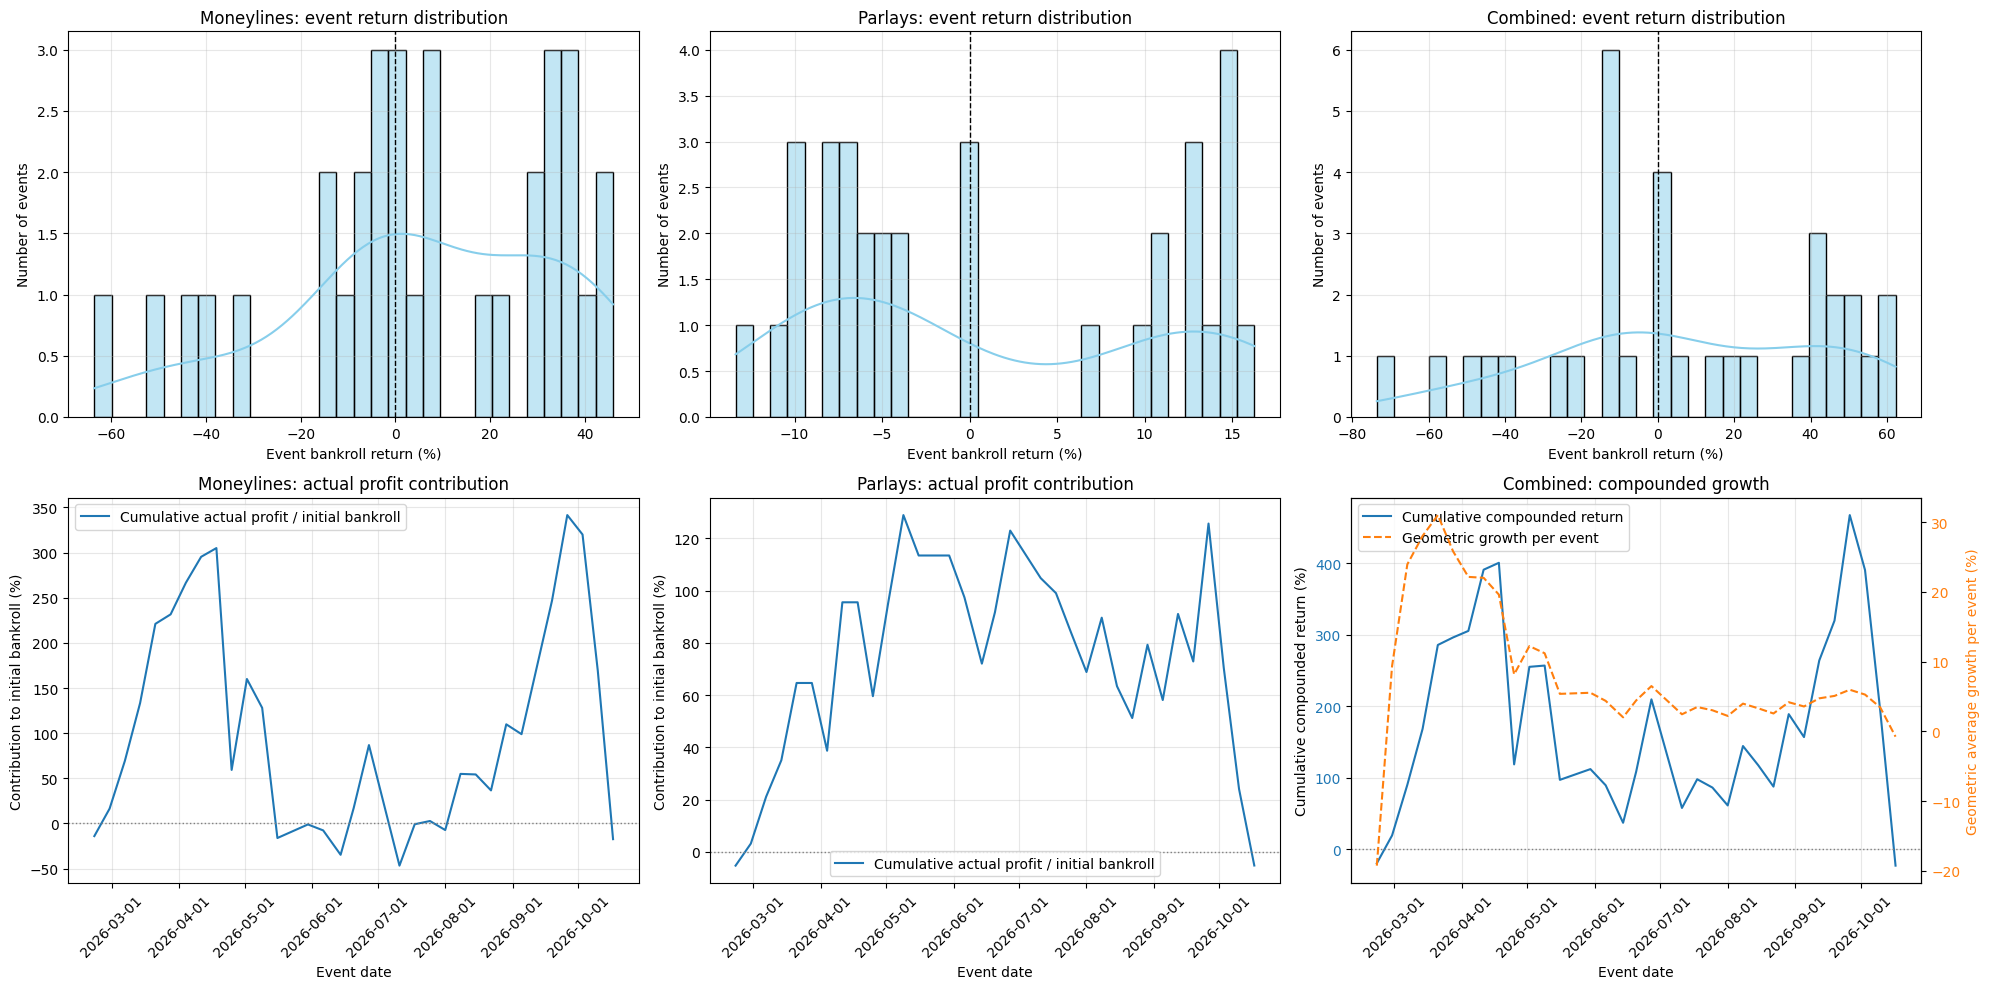

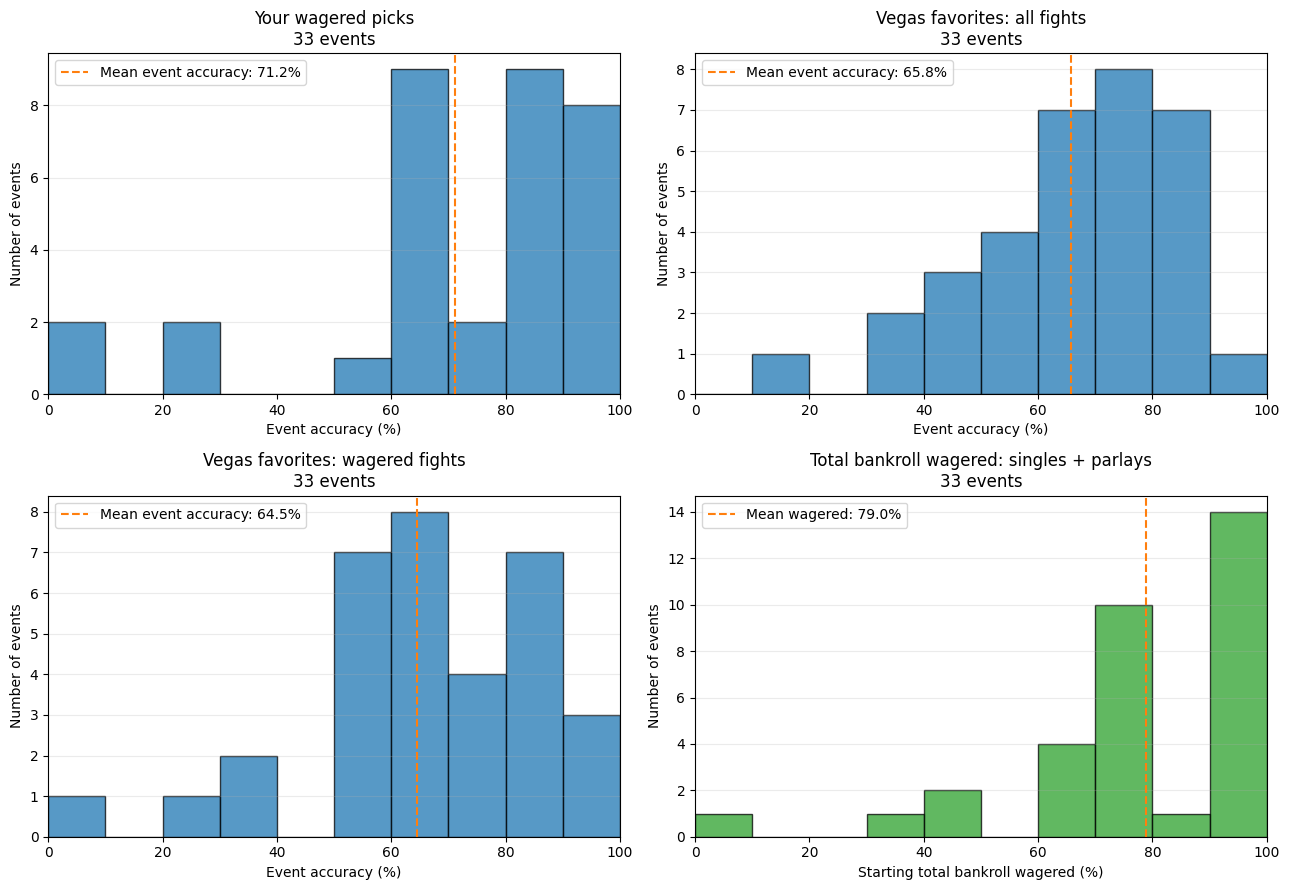

In [6]:
prediction_options = dict(split="test", model_type="open")

moneylines, parlays = simulate_and_plot(
    "open", initial_bankroll=500, use_decay=False, predictions_path=prediction_paths["open"], **prediction_options,
)
plot_bankroll_distributions(moneylines, parlays)
fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="open"
)

Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\test_logit_open_with_close1.csv
close1: decay enabled


{'z': 1.33,
 'N': 1090,
 'N_parlay': 964,
 'mdd': 0.5800000000000001,
 'mdd_parlay': 0.01,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 41.04241524345824,
  'k_up': 0.3849900028407934,
  'k_parlay_down': 15.445551695494085,
  'k_parlay_up': 28.771654125641508},
 'moneyline_min_american': -225.0}

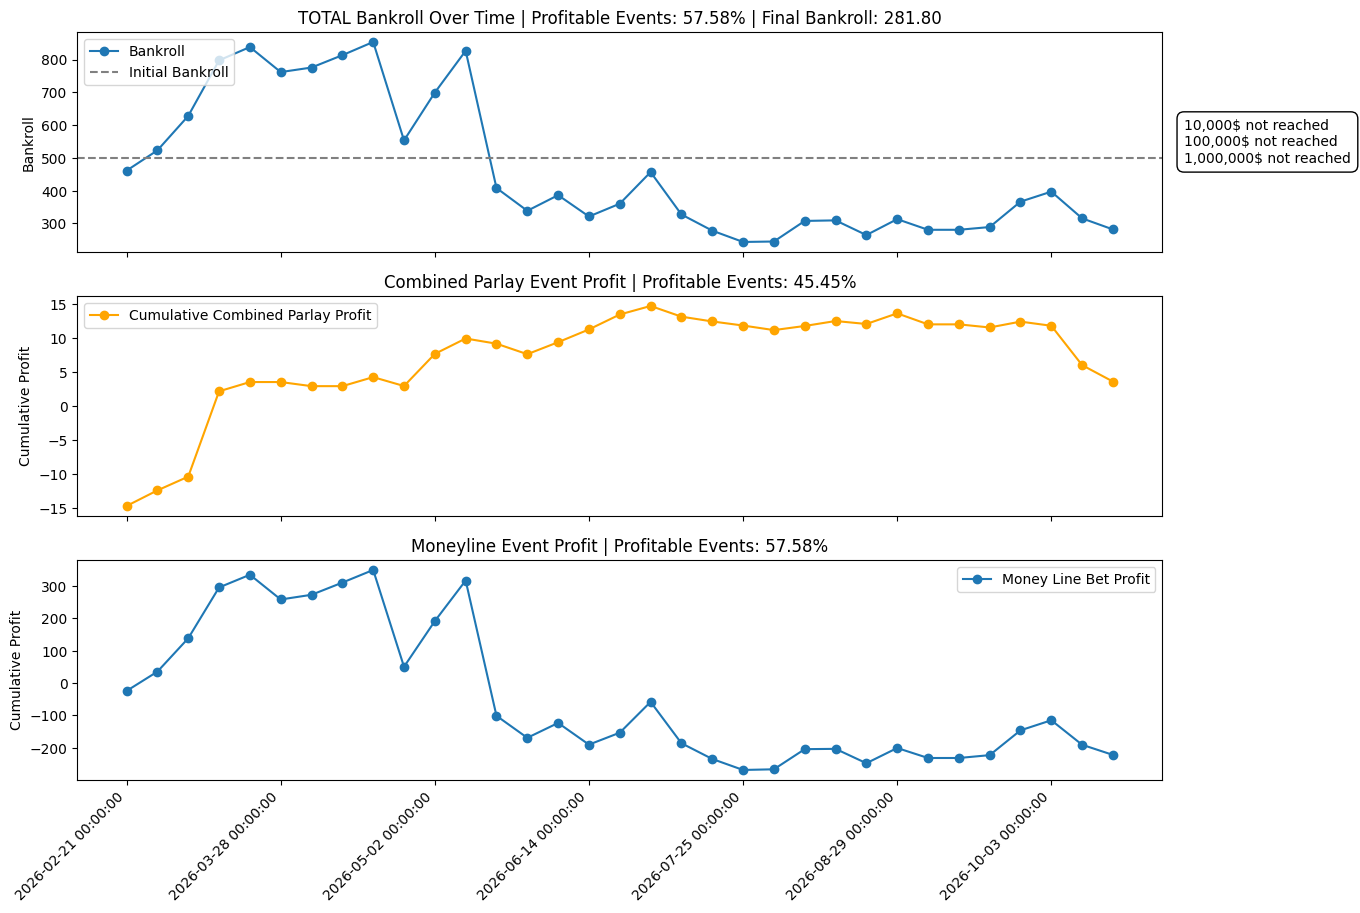

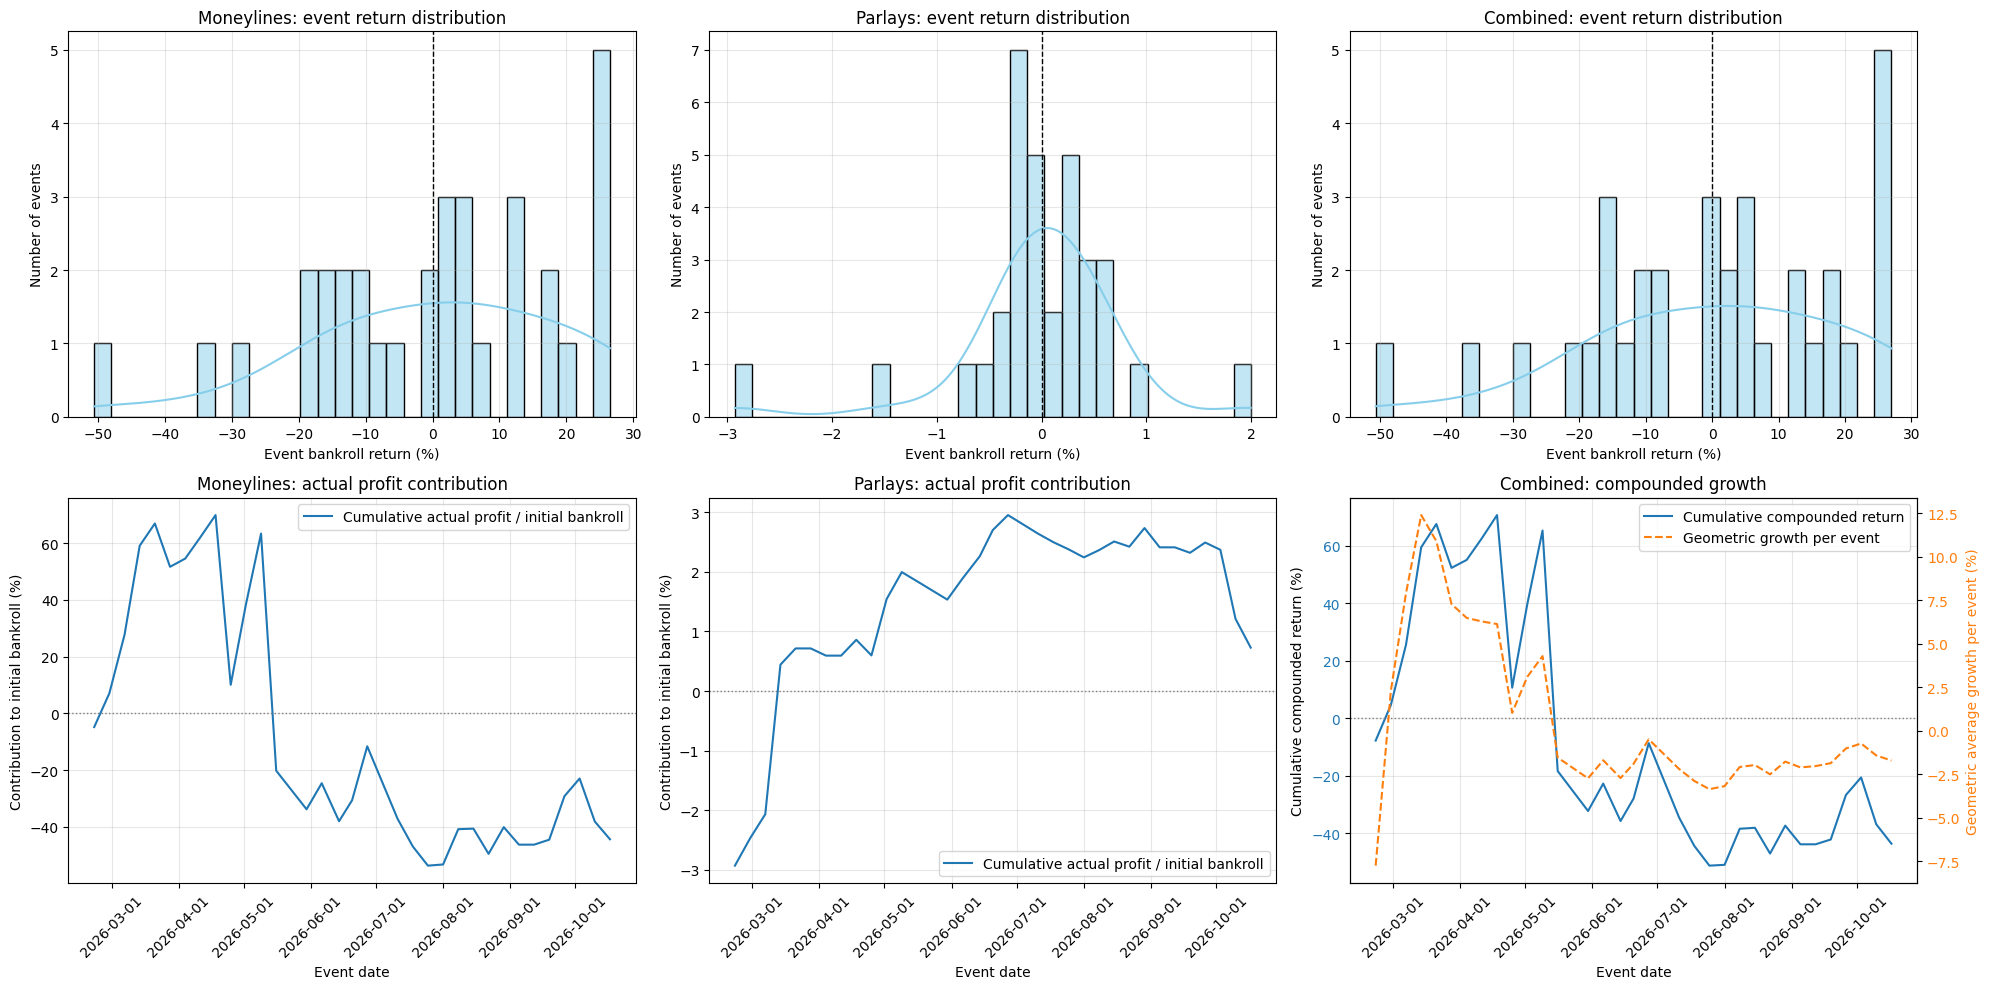

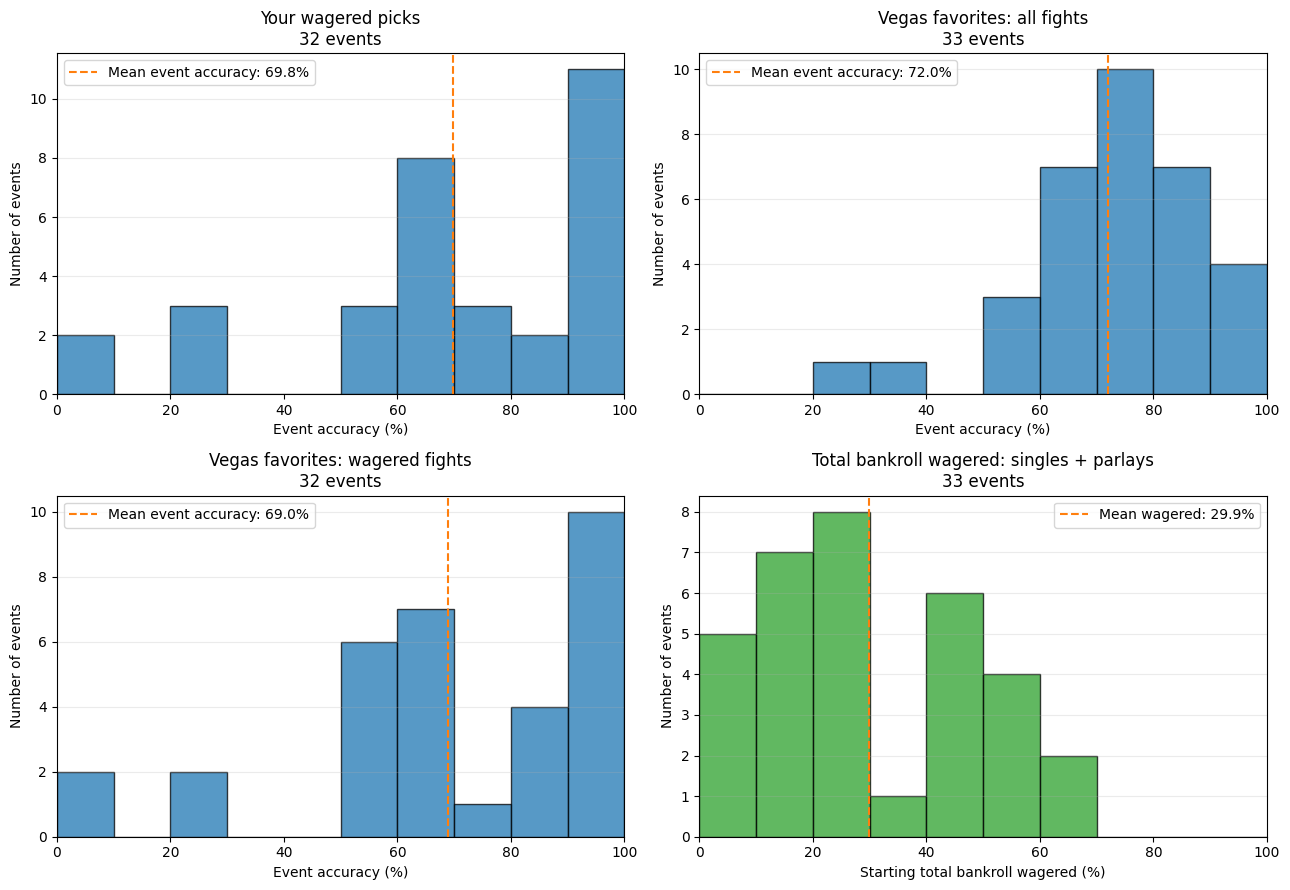

In [7]:

moneylines, parlays = simulate_and_plot(
    "close1", initial_bankroll=500, use_decay=True, predictions_path=prediction_paths["close1"], **prediction_options,
)
plot_bankroll_distributions(moneylines, parlays)
fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="close1"
)

Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\test_logit_open_with_close2.csv
close2: decay enabled


{'z': 1.06,
 'N': 123,
 'N_parlay': 43,
 'mdd': 0.56,
 'mdd_parlay': 0.26,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 38.139591603478735,
  'k_up': 0.0019978853920430734,
  'k_parlay_down': 1.614251913567895,
  'k_parlay_up': 0.07383383104952941},
 'moneyline_min_american': -200.0}

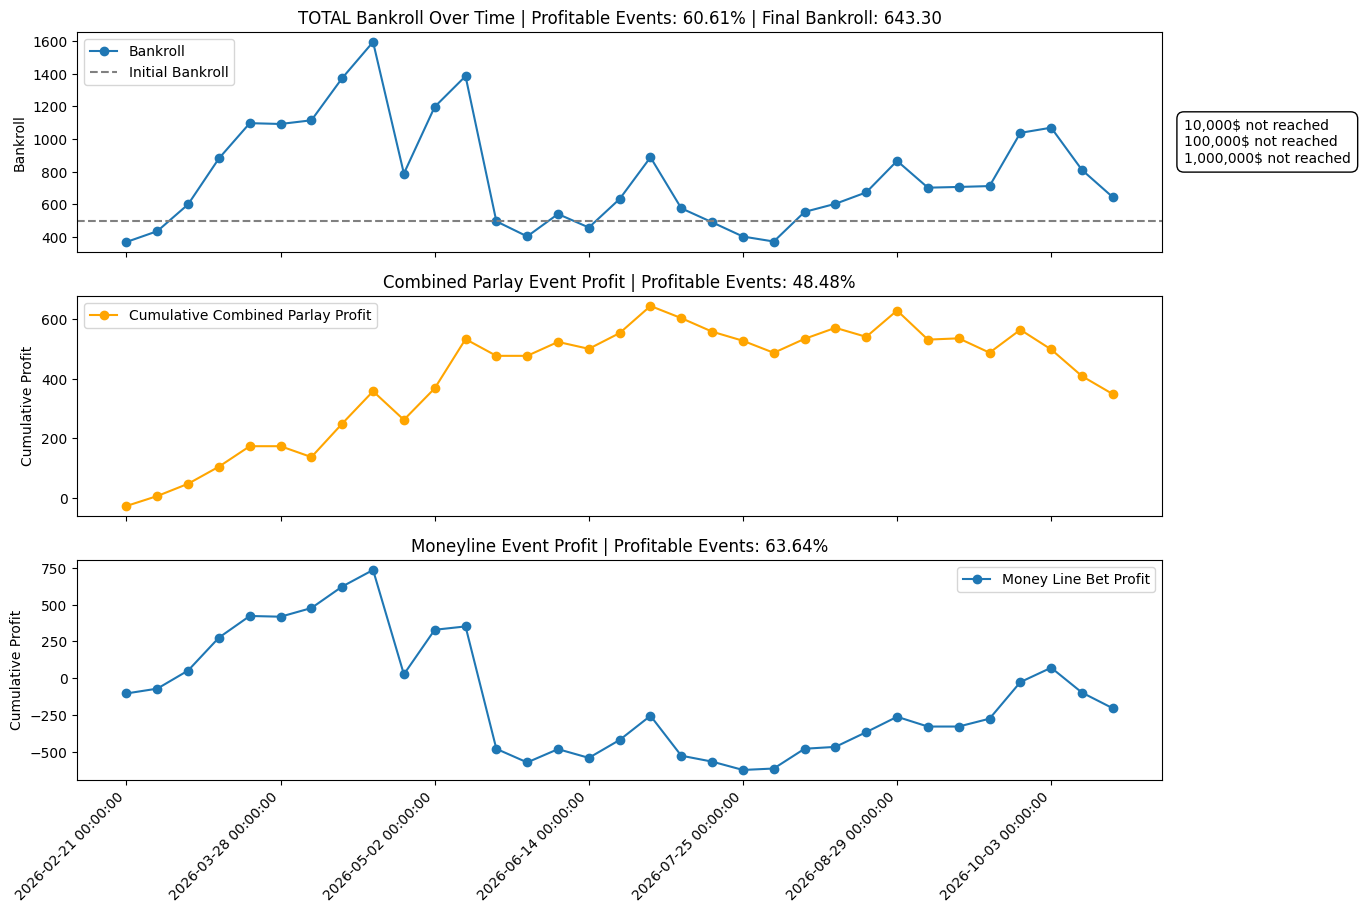

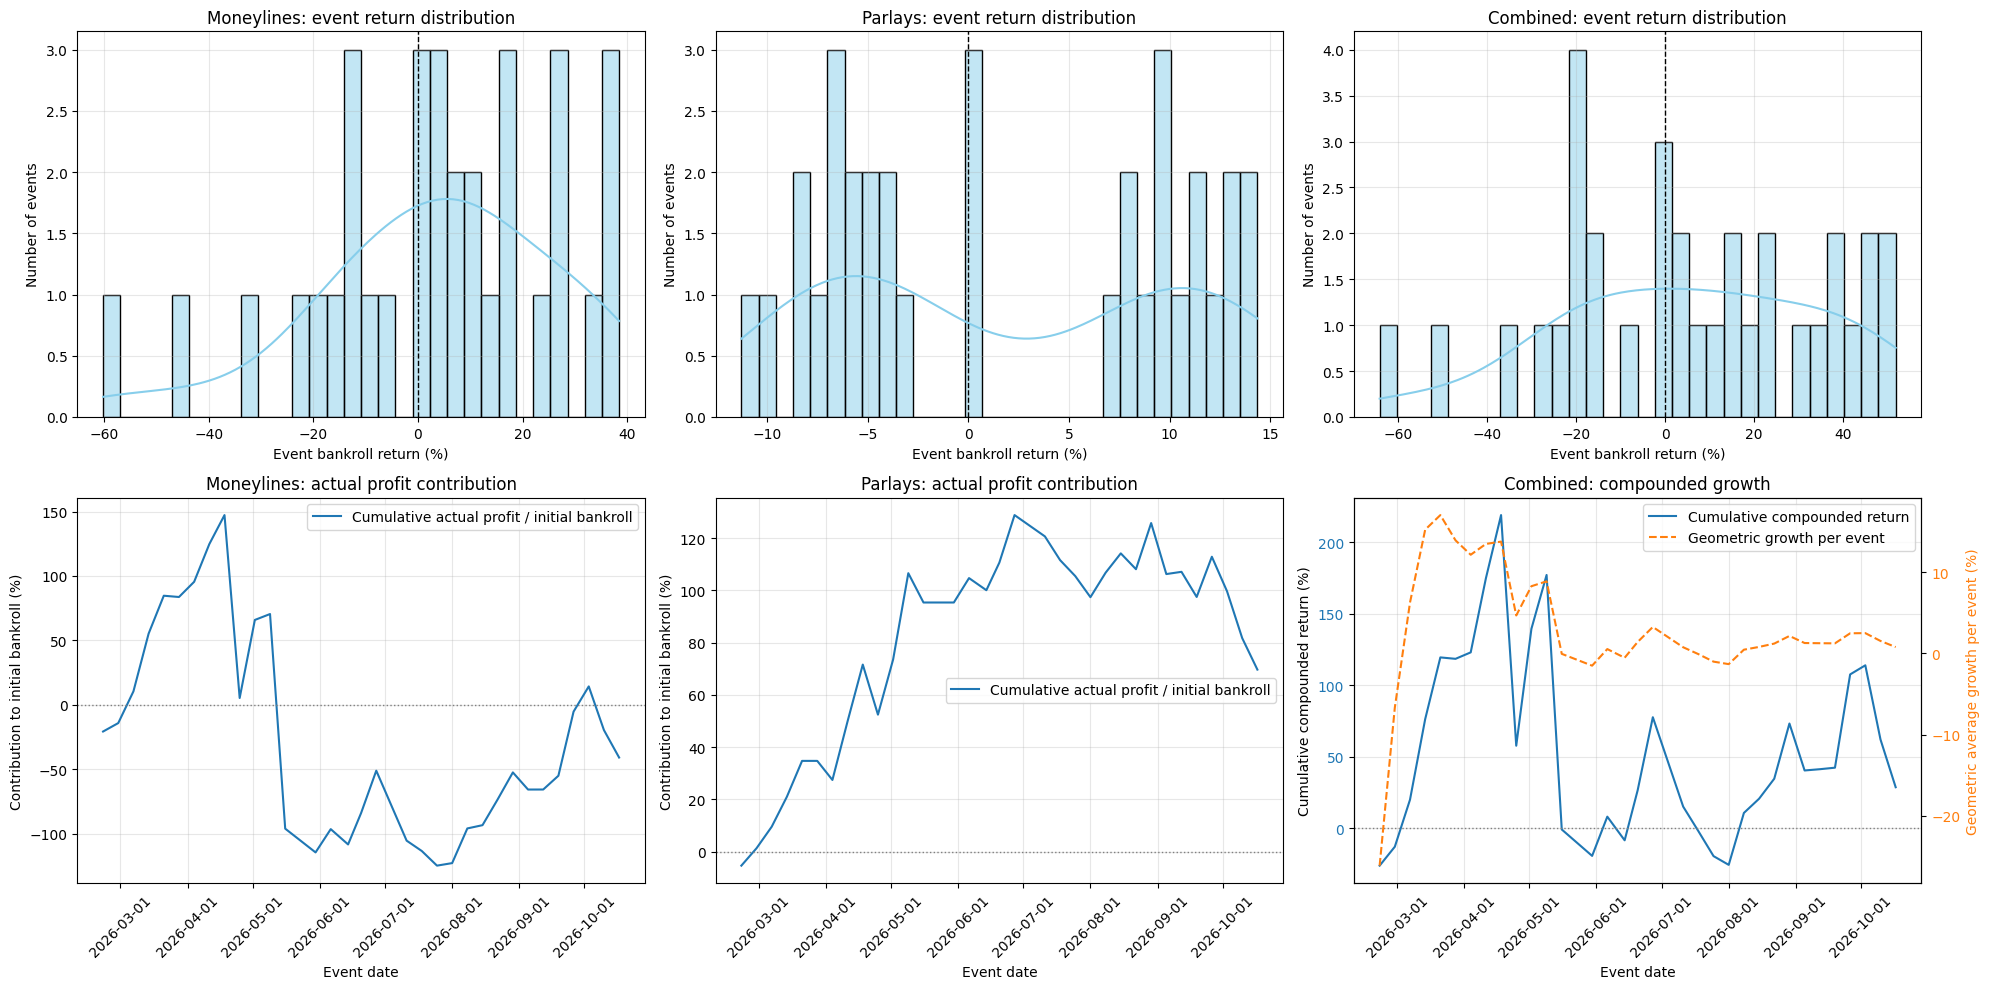

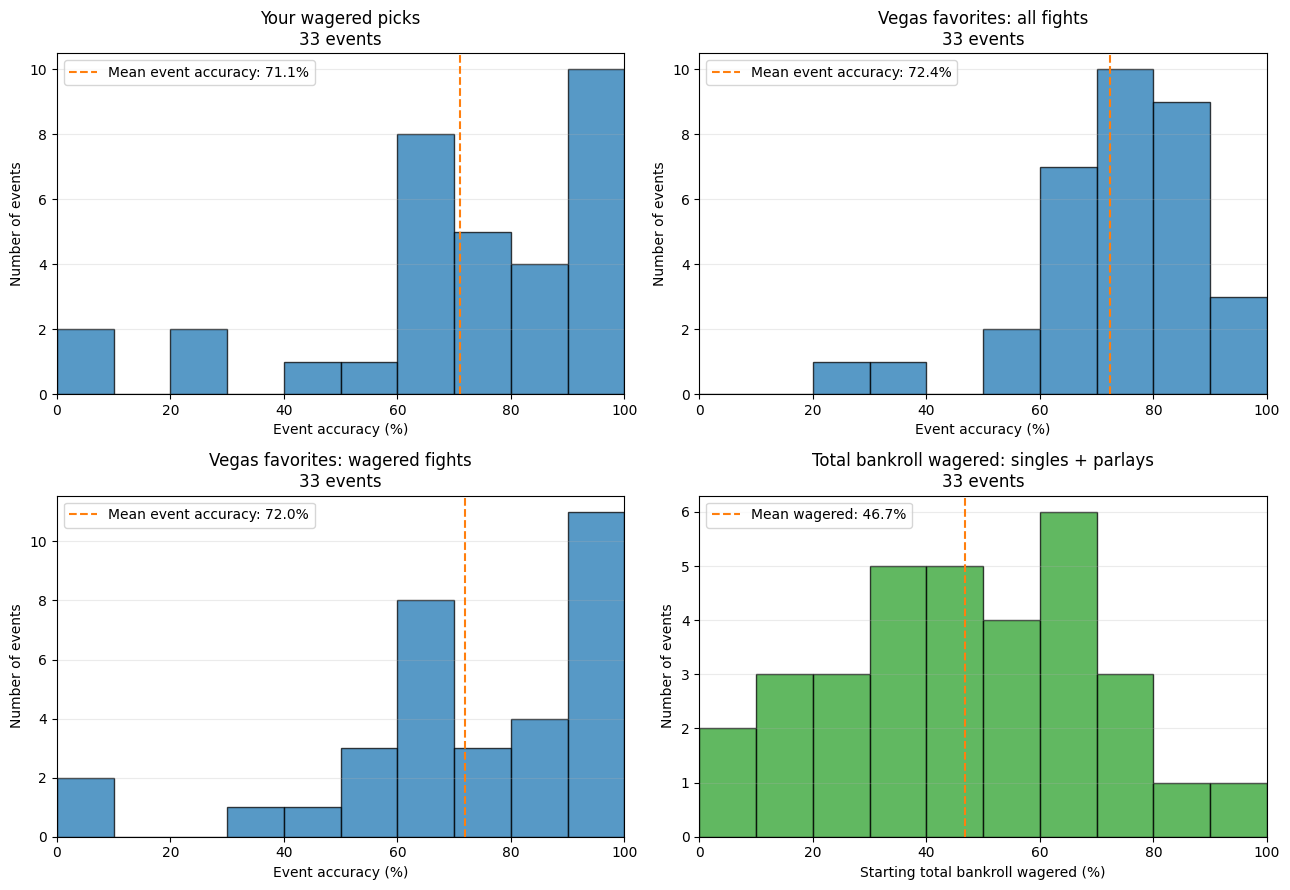

In [8]:

moneylines, parlays = simulate_and_plot(
    "close2", initial_bankroll=500, use_decay=True, predictions_path=prediction_paths["close2"], **prediction_options,
)
plot_bankroll_distributions(moneylines, parlays)
fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="close2"
)